In [1]:
import schemdraw
from schemdraw import elements as elm
from schemdraw import logic
from schemdraw import flow
from schemdraw import dsp

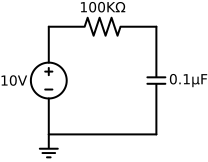

In [2]:
with schemdraw.Drawing(show=False) as d:
    elm.Resistor().label('100KΩ')
    elm.Capacitor().down().label('0.1μF', loc='bottom')
    elm.Line().left()
    elm.Ground()
    elm.SourceV().up().label('10V')

schemdraw.from_dict(schemdraw.to_dict(d))

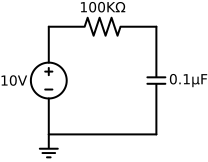

In [3]:
schemdraw.from_json(schemdraw.to_json(d))

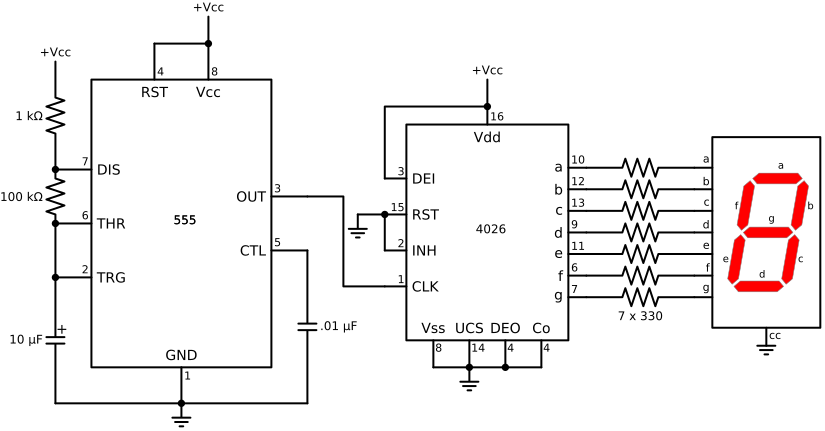

In [4]:
# Ic, IcPins
with schemdraw.Drawing(show=False) as d:
    d.config(fontsize=12)
    IC555 = elm.Ic555(size=(5,8))
    gnd = elm.Ground().at(IC555.GND)
    elm.Dot()
    elm.Resistor().endpoints(IC555.DIS, IC555.THR).label('100 kΩ')
    elm.Resistor().up().at(IC555.DIS).label('1 kΩ').label('+Vcc', 'right')
    elm.Line().endpoints(IC555.THR, IC555.TRG)
    elm.Capacitor(polar=True).at(IC555.TRG).toy(gnd.start).label('10 μF')
    elm.Line().tox(gnd.start)
    elm.Capacitor().at(IC555.CTL).toy(gnd.start).label('.01 μF', 'bottom')
    elm.Line().tox(gnd.start)

    elm.Dot().at(IC555.DIS)
    elm.Dot().at(IC555.THR)
    elm.Dot().at(IC555.TRG)
    elm.Line().endpoints(IC555.RST,IC555.Vcc).dot()
    elm.Line().up(d.unit/4).label('+Vcc', 'right')
    d.move_from(IC555.OUT, dx=5, dy=-1)

    IC4026 = (elm.Ic()
              .pin('L', 'CLK', pin='1')
              .pin('L', 'INH', pin='2') # Inhibit
              .pin('L', 'RST', pin='15')
              .pin('L', 'DEI', pin='3') # Display Enable In
              .pin('B', 'Vss', pin='8')
              .pin('T', 'Vdd', pin='16')
              .pin('B', 'UCS', pin='14') # Ungated C Segment
              .pin('B', 'DEO', pin='4')  # Display Enable Out
              .pin('B', 'Co', pin='4')   # Carry out
              .pin('R', 'g', pin='7')
              .pin('R', 'f', pin='6')
              .pin('R', 'e', pin='11')
              .pin('R', 'd', pin='9')
              .pin('R', 'c', pin='13')
              .pin('R', 'b', pin='12')
              .pin('R', 'a', pin='10')
              .side('B', spacing=1, pad=.75, leadlen=.75)
              .side('L', spacing=1, pad=1.5, leadlen=.6)
              .label('4026').right().anchor('center'))
    elm.Wire('c').at(IC555.OUT).to(IC4026.CLK)
    elm.Line().endpoints(IC4026.INH, IC4026.RST).dot()
    elm.Line().left(d.unit/4)
    elm.Ground()
    elm.Wire('|-').at(IC4026.DEI).to(IC4026.Vdd).dot()
    elm.Line().up(d.unit/4).label('+Vcc', 'right')
    elm.Line().at(IC4026.Vss).tox(IC4026.UCS).dot()
    elm.Ground()
    elm.Line().tox(IC4026.DEO).dot()
    elm.Line().tox(IC4026.Co)

    elm.Resistor().right().at(IC4026.a)
    disp = elm.SevenSegment(cathode=True).anchor('a')
    elm.Resistor().at(IC4026.b)
    elm.Resistor().at(IC4026.c)
    elm.Resistor().at(IC4026.d)
    elm.Resistor().at(IC4026.e)
    elm.Resistor().at(IC4026.f)
    elm.Resistor().at(IC4026.g).label('7 x 330', loc='bottom')
    elm.Ground(lead=False).at(disp.cathode)

schemdraw.from_dict(schemdraw.to_dict(d))

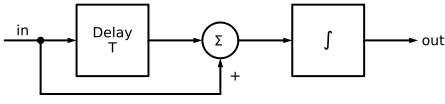

In [5]:
# DSP
with schemdraw.Drawing(show=False) as d:
    dsp.Line().length(d.unit/3).label('in')
    inpt = dsp.Dot()
    dsp.Arrow().length(d.unit/3)
    delay = dsp.Box(w=2, h=2).anchor('W').label('Delay\nT')
    dsp.Arrow().right(d.unit/2).at(delay.E)
    sm = dsp.SumSigma()
    dsp.Arrow().at(sm.E).length(d.unit/2)
    intg = dsp.Box(w=2, h=2).anchor('W').label(r'$\int$')
    dsp.Arrow().right(d.unit/2).at(intg.E).label('out', loc='right')
    dsp.Line().down(d.unit/2).at(inpt.center)
    dsp.Line().tox(sm.S)
    dsp.Arrow().toy(sm.S).label('+', loc='bot')

schemdraw.from_dict(schemdraw.to_dict(d))

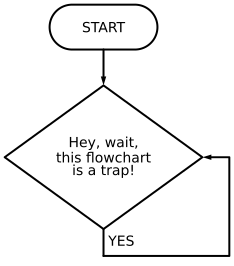

In [6]:
# Flowcharts
with schemdraw.Drawing(show=False) as d:
    flow.Start().label('START')
    flow.Arrow().down(d.unit/3)
    h = flow.Decision(w=5.5, h=4, S='YES').label('Hey, wait,\nthis flowchart\nis a trap!')
    flow.Line().down(d.unit/4)
    flow.Wire('c', k=3.5, arrow='->').to(h.E)
schemdraw.from_dict(schemdraw.to_dict(d))

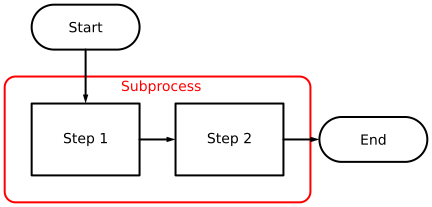

In [7]:
# Containers
with schemdraw.Drawing(unit=1, show=False) as d:
    flow.Start().label('Start')
    flow.Arrow().down(1.5)
    with d.container() as c:
        flow.Box().label('Step 1').drop('E')
        flow.Arrow().right()
        flow.Box().label('Step 2')
        c.color('red')
        c.label('Subprocess', loc='N', halign='center', valign='top')
    flow.Arrow().right()
    flow.Start().label('End').anchor('W')
schemdraw.from_dict(schemdraw.to_dict(d))

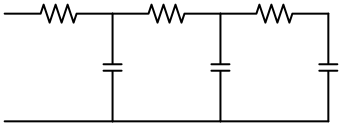

In [8]:
# ElementDrawings

with schemdraw.Drawing(show=False) as d1:
    d1 += elm.Resistor()
    d1.push()
    d1 += elm.Capacitor().down()
    d1 += elm.Line().left()
    d1.pop()

with schemdraw.Drawing(show=False) as d2:  # Add a second drawing
    for i in range(3):
        d2 += elm.ElementDrawing(d1)   # Add the first drawing to it 3 times

schemdraw.from_dict(schemdraw.to_dict(d2))

In [9]:
# Direct from hand-written TOML

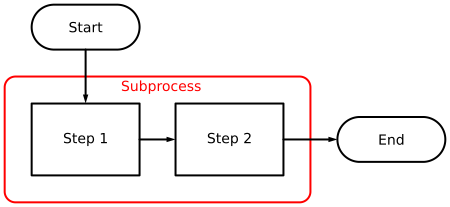

In [10]:
t = r'''
config = {unit=1}

elements = [
    {name="Start", label.text="Start"},
    {name="Arrow", d="down", length=1.5},
    {name="Container", color="red", elements=[
        {name="Box", label.text="Step 1", drop="E"},
        {name="Arrow", d="right"},
        {name="Box", label.text="Step 2"}
    ], label.text="Subprocess", label.loc="N", label.halign="center"},
    {name="Arrow", d="right", length=1.5},
    {name="Start", anchor="W", label.text="End"}
    ]
'''
schemdraw.from_toml(t)

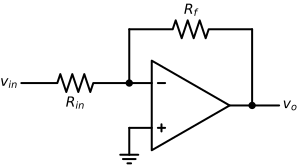

In [11]:
    toml = '''
    elements = [
        {id="op", name="Opamp", args={leads=true}},
        {name="Line", d="down", length="unit/4", at="op.in2"},
        {name="Ground", args={lead=false}},
        {name="Dot", at="op.in1"},
        {id="Rin", name="Resistor", at="op.in1", d="left", labels.1.text="$R_{in}$", labels.1.loc="bottom", labels.2.text="$v_{in}$", labels.2.loc="left"},
        {name="Line", d="up", length="unit/2", at="op.in1"},
        {name="Resistor", tox="op.out", label.text="$R_f$"},
        {name="Line", toy="op.out", dot=true},
        {name="Line", d="right", length="unit/4", at="op.out", label.text="$v_{o}$", label.loc="right"}
    ]
    '''
    schemdraw.from_toml(toml)